Dispositivo usado: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Train shapes: X=(11997, 13), y=(11997,)
Val shapes: X=(4000, 13), y=(4000,)
Test shapes: X=(4000, 13), y=(4000,)

===== Entrenando modelo: linear =====
Epoch 10/50 - Train Loss: 0.5148 - Val Loss: 0.5101
Epoch 20/50 - Train Loss: 0.5067 - Val Loss: 0.5047
Epoch 30/50 - Train Loss: 0.5046 - Val Loss: 0.5035
Epoch 40/50 - Train Loss: 0.5041 - Val Loss: 0.5029
Epoch 50/50 - Train Loss: 0.5038 - Val Loss: 0.5026
Resultados linear: F1=0.8124, Accuracy=0.7980, Tiempo inf (us/muestra)=119.08

===== Entrenando modelo: mlp_simple =====
Epoch 10/50 - Train Loss: 0.3552 - Val Loss: 0.3571
Epoch 20/50 - Train Loss: 0.3327 - Val Loss: 0.3433
Epoch 30/50 - Train Loss: 0.3234 - Val Loss: 0.3375
Epoch 40/50 - Train Loss: 0.3159 - Val Loss: 0.3276
Epoch 50/50 - Train Loss: 0.3111 - Val Loss: 0.3255
Resultados mlp_simple: F1=0.8578, Accuracy=0.8592, Tiempo inf (us/muestra)=250.92

===== Entrenando modelo: mlp_residual =====
Epoch 10/50 

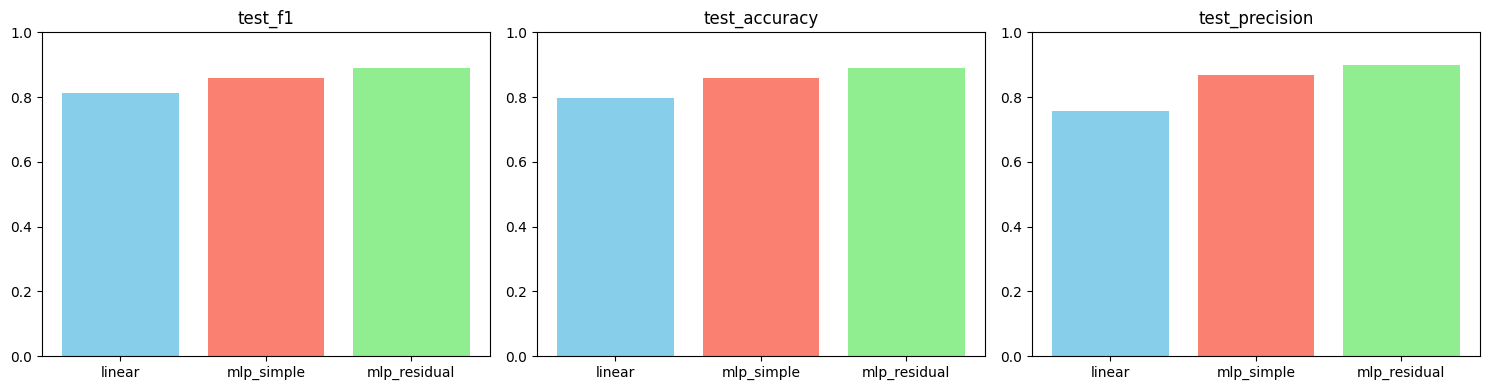

In [1]:
# -*- coding: utf-8 -*-
# notebook: entrenamiento_modelos_base.ipynb

# ## 1. Importación de librerías

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
import pandas as pd
import os
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

# Verificar disponibilidad de CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo usado: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ## 2. Carga de datos

data_dir = "."  # misma carpeta que el notebook
X_train = np.load(os.path.join(data_dir, "X_train.npy"))
y_train = np.load(os.path.join(data_dir, "y_train.npy"))
X_val = np.load(os.path.join(data_dir, "X_val.npy"))
y_val = np.load(os.path.join(data_dir, "y_val.npy"))
X_test = np.load(os.path.join(data_dir, "X_test.npy"))
y_test = np.load(os.path.join(data_dir, "y_test.npy"))

print(f"Train shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Val shapes: X={X_val.shape}, y={y_val.shape}")
print(f"Test shapes: X={X_test.shape}, y={y_test.shape}")

# Convertir a tensores y crear DataLoaders
batch_size = 64

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

input_dim = X_train.shape[1]

# ## 3. Definición de los modelos simples

class ModeloLineal(nn.Module):
    """Regresión logística: una capa lineal + sigmoide implícita (BCEWithLogitsLoss)"""
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
    def forward(self, x):
        return self.linear(x)

class MLPSimple(nn.Module):
    """MLP con una capa oculta de 64 neuronas y ReLU"""
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

class MLPResidual(nn.Module):
    """MLP con conexión residual (similar a residual_mlp)"""
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        # Si input_dim != hidden_dim, usamos un proyector para la residual
        self.shortcut = nn.Linear(input_dim, hidden_dim) if input_dim != hidden_dim else nn.Identity()
        self.fc_out = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        identity = self.shortcut(x)
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = out + identity   # conexión residual
        out = self.relu(out)
        out = self.fc_out(out)
        return out

# ## 4. Función de entrenamiento y evaluación

def entrenar_modelo(model, train_loader, val_loader, epochs=50, lr=0.001, patience=5):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float('inf')
    patience_counter = 0
    train_start = time.time()
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * X_batch.size(0)
        train_loss /= len(train_loader.dataset)
        
        # Validación
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                val_loss += loss.item() * X_batch.size(0)
        val_loss /= len(val_loader.dataset)
        
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            # guardar mejor modelo (opcional)
            torch.save(model.state_dict(), 'best_model_temp.pth')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping en epoch {epoch+1}")
                break
    
    train_end = time.time()
    training_time = train_end - train_start
    
    # Cargar el mejor modelo
    model.load_state_dict(torch.load('best_model_temp.pth'))
    os.remove('best_model_temp.pth')
    return model, training_time

def evaluar_modelo(model, test_loader):
    model.eval()
    y_true = []
    y_pred = []
    inference_times = []
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            start_time = time.time()
            outputs = model(X_batch)
            end_time = time.time()
            inference_times.append(end_time - start_time)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    
    # Métricas
    f1 = f1_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    
    # Tiempo de inferencia por muestra (microsegundos)
    avg_inference_time_us = (sum(inference_times) / len(inference_times)) * 1e6 / len(next(iter(test_loader))[0])  # por muestra
    # Alternativa más precisa: medir sobre todo el test set
    # Mejor medir sobre cada sample individualmente:
    sample_times = []
    model.eval()
    with torch.no_grad():
        for X_batch, _ in test_loader:
            for i in range(len(X_batch)):
                x_sample = X_batch[i:i+1].to(device)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                start = time.time()
                _ = model(x_sample)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                end = time.time()
                sample_times.append((end - start) * 1e6)  # microsegundos
    inference_us_per_sample = np.mean(sample_times)
    
    # Tamaño del modelo en MB
    param_size = sum(p.numel() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())
    size_mb = (param_size + buffer_size) / (1024 ** 2)
    
    return f1, accuracy, precision, recall, inference_us_per_sample, size_mb

# ## 5. Entrenamiento y evaluación de los tres modelos

modelos = {
    "linear": ModeloLineal(input_dim),
    "mlp_simple": MLPSimple(input_dim, hidden_dim=64),
    "mlp_residual": MLPResidual(input_dim, hidden_dim=64)
}

resultados = []

for nombre, modelo in modelos.items():
    print(f"\n===== Entrenando modelo: {nombre} =====")
    modelo_entrenado, tiempo_entrenamiento = entrenar_modelo(modelo, train_loader, val_loader, epochs=50)
    f1, acc, prec, rec, inf_time_us, size_mb = evaluar_modelo(modelo_entrenado, test_loader)
    resultados.append({
        "architecture": nombre,
        "sampler": "simple",  # no aplica búsqueda de hiperparámetros
        "test_f1": f1,
        "test_accuracy": acc,
        "test_precision": prec,
        "test_recall": rec,
        "inference_us_per_sample": inf_time_us,
        "training_time_seconds": tiempo_entrenamiento,
        "size_mb": size_mb
    })
    print(f"Resultados {nombre}: F1={f1:.4f}, Accuracy={acc:.4f}, Tiempo inf (us/muestra)={inf_time_us:.2f}")

# ## 6. Guardar resultados

df_resultados = pd.DataFrame(resultados)
df_resultados.to_csv("resultados_modelos_base.csv", index=False)
print("\nResultados guardados en 'resultados_modelos_base.csv'")
print(df_resultados.to_string())

# ## 7. (Opcional) Comparativa visual rápida

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = ['test_f1', 'test_accuracy', 'test_precision']
for i, metric in enumerate(metrics):
    axes[i].bar(df_resultados['architecture'], df_resultados[metric], color=['skyblue', 'salmon', 'lightgreen'])
    axes[i].set_title(metric)
    axes[i].set_ylim(0, 1)
plt.tight_layout()
plt.show()

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Train: (11997, 13), (11997,)
Val:   (4000, 13), (4000,)
Test:  (4000, 13), (4000,)
Dimensión de entrada: 13

🚀 Entrenando linear...
Epoch  10 | Train Loss: 0.5152 | Val Loss: 0.5110
Epoch  20 | Train Loss: 0.5053 | Val Loss: 0.5040
Epoch  30 | Train Loss: 0.5040 | Val Loss: 0.5031
Epoch  40 | Train Loss: 0.5037 | Val Loss: 0.5024
Epoch  50 | Train Loss: 0.5035 | Val Loss: 0.5021
Early stopping en epoch 50
✅ linear          | F1: 0.8153 | Inf. (us): 144.33 | Size (MB): 0.0001

🚀 Entrenando mlp_simple...
Epoch  10 | Train Loss: 0.3569 | Val Loss: 0.3605
Epoch  20 | Train Loss: 0.3359 | Val Loss: 0.3486
Epoch  30 | Train Loss: 0.3259 | Val Loss: 0.3377
Epoch  40 | Train Loss: 0.3180 | Val Loss: 0.3318
Early stopping en epoch 48
✅ mlp_simple      | F1: 0.8651 | Inf. (us): 389.33 | Size (MB): 0.0037

🚀 Entrenando mlp_residual...
Epoch  10 | Train Loss: 0.3217 | Val Loss: 0.3330
Epoch  20 | Train Loss: 0.2972 | Val Loss: 0.3174
Ep

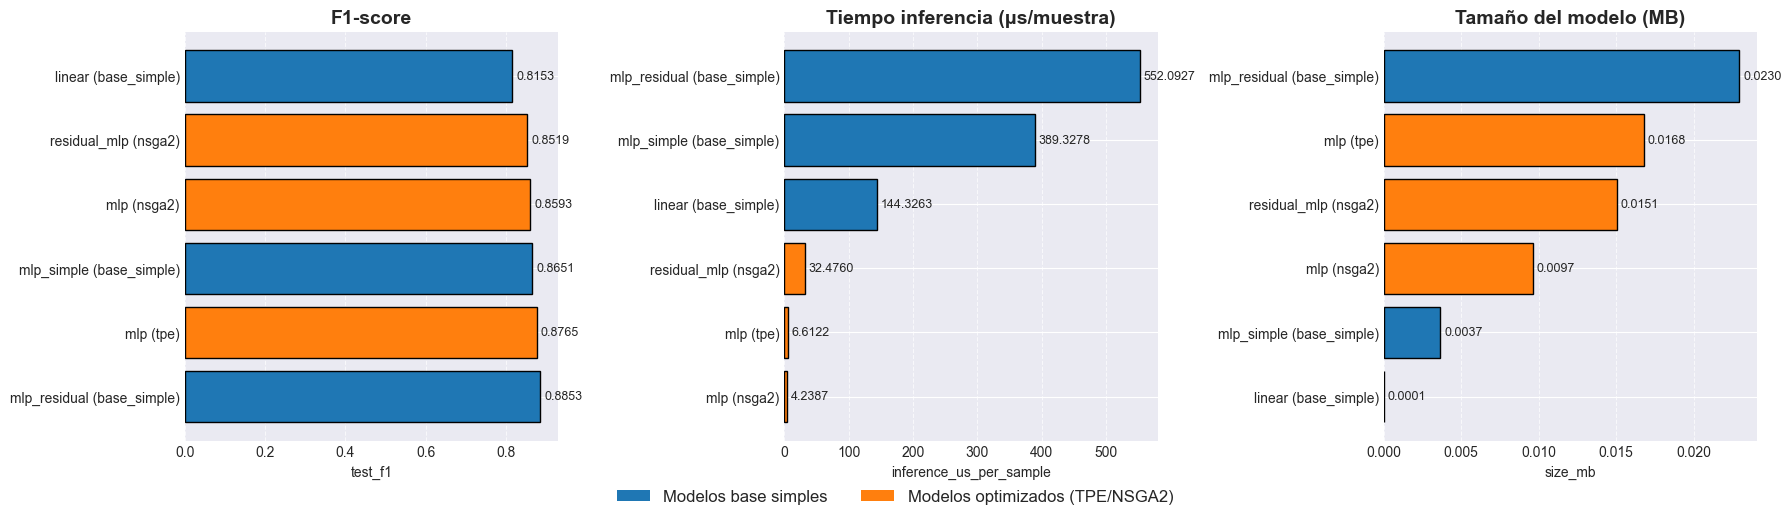

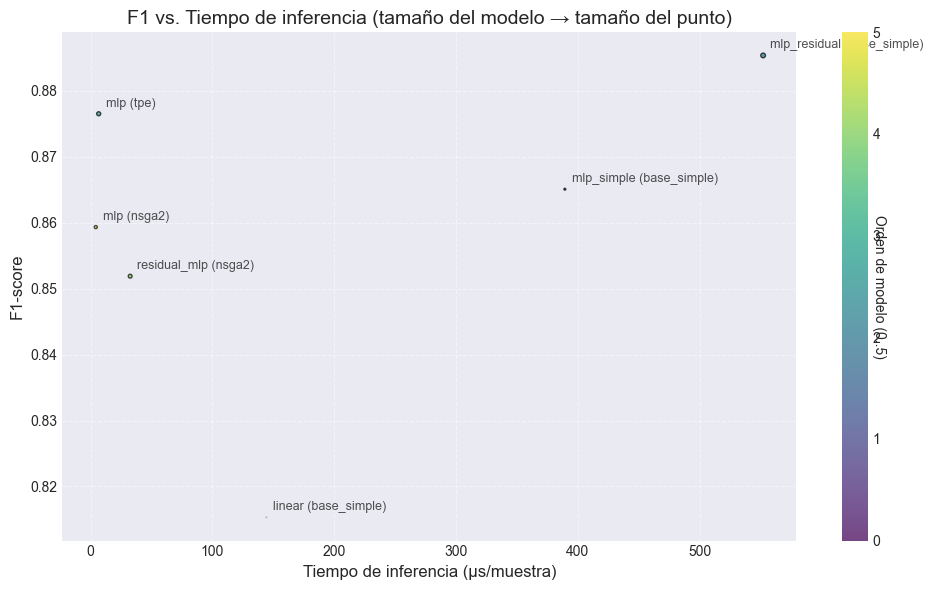


📊 Tabla comparativa ordenada por F1-score (mejores primero):
                modelo_nombre  test_f1  inference_us_per_sample  size_mb
2  mlp_residual (base_simple)   0.8853                 552.0927   0.0230
3                   mlp (tpe)   0.8765                   6.6122   0.0168
1    mlp_simple (base_simple)   0.8651                 389.3278   0.0037
5                 mlp (nsga2)   0.8593                   4.2387   0.0097
4        residual_mlp (nsga2)   0.8519                  32.4760   0.0151
0        linear (base_simple)   0.8153                 144.3263   0.0001


In [2]:
# -*- coding: utf-8 -*-
# COMPARATIVA DE 6 MODELOS: 3 bases simples + 3 optimizados (TPE/NSGA2)

# %% [markdown]
# ## 1. Configuración inicial e importación de librerías

# %%
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

# Configuración de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Verificar CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# %% [markdown]
# ## 2. Carga de datos desde archivos .npy

# %%
data_dir = "."  # Carpeta donde están los archivos
X_train = np.load(os.path.join(data_dir, "X_train.npy"))
y_train = np.load(os.path.join(data_dir, "y_train.npy"))
X_val   = np.load(os.path.join(data_dir, "X_val.npy"))
y_val   = np.load(os.path.join(data_dir, "y_val.npy"))
X_test  = np.load(os.path.join(data_dir, "X_test.npy"))
y_test  = np.load(os.path.join(data_dir, "y_test.npy"))

print(f"Train: {X_train.shape}, {y_train.shape}")
print(f"Val:   {X_val.shape}, {y_val.shape}")
print(f"Test:  {X_test.shape}, {y_test.shape}")

# Convertir a tensores
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_t   = torch.tensor(X_val, dtype=torch.float32)
y_val_t   = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
X_test_t  = torch.tensor(X_test, dtype=torch.float32)
y_test_t  = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

batch_size = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size)

input_dim = X_train.shape[1]
print(f"Dimensión de entrada: {input_dim}")

# %% [markdown]
# ## 3. Definición de los 3 modelos simples

# %%
class ModeloLineal(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
    def forward(self, x):
        return self.linear(x)

class MLPSimple(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

class MLPResidual(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.shortcut = nn.Linear(input_dim, hidden_dim) if input_dim != hidden_dim else nn.Identity()
        self.fc_out = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = self.relu(out + identity)
        return self.fc_out(out)

# %% [markdown]
# ## 4. Funciones de entrenamiento y evaluación

# %%
def entrenar_modelo(model, train_loader, val_loader, epochs=50, lr=0.001, patience=5):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float('inf')
    patience_counter = 0
    train_start = time.time()
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * Xb.size(0)
        train_loss /= len(train_loader.dataset)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                val_loss += criterion(model(Xb), yb).item() * Xb.size(0)
        val_loss /= len(val_loader.dataset)
        
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), 'temp_best.pth')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping en epoch {epoch+1}")
                break
    
    train_time = time.time() - train_start
    model.load_state_dict(torch.load('temp_best.pth'))
    os.remove('temp_best.pth')
    return model, train_time

def evaluar_modelo(model, test_loader):
    model.eval()
    y_true, y_pred = [], []
    sample_times_us = []
    
    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(device)
            # Medir inferencia por muestra (para precisión)
            for i in range(len(Xb)):
                x_sample = Xb[i:i+1]
                if device.type == 'cuda':
                    torch.cuda.synchronize()
                start = time.time()
                out = model(x_sample)
                if device.type == 'cuda':
                    torch.cuda.synchronize()
                sample_times_us.append((time.time() - start) * 1e6)
            # Predicciones en batch para métricas
            outputs = model(Xb)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            y_true.extend(yb.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    
    f1 = f1_score(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    inf_us = np.mean(sample_times_us)
    
    # Tamaño del modelo en MB
    param_size = sum(p.numel() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())
    size_mb = (param_size + buffer_size) / (1024 ** 2)
    
    return f1, acc, prec, rec, inf_us, size_mb

# %% [markdown]
# ## 5. Entrenamiento de los 3 modelos simples

# %%
modelos_simples = {
    "linear": ModeloLineal(input_dim),
    "mlp_simple": MLPSimple(input_dim),
    "mlp_residual": MLPResidual(input_dim)
}

resultados_simples = []

for nombre, modelo in modelos_simples.items():
    print(f"\n🚀 Entrenando {nombre}...")
    modelo_ent, tiempo_ent = entrenar_modelo(modelo, train_loader, val_loader)
    f1, acc, prec, rec, inf_us, size_mb = evaluar_modelo(modelo_ent, test_loader)
    resultados_simples.append({
        "architecture": nombre,
        "sampler": "base_simple",
        "test_f1": f1,
        "test_accuracy": acc,
        "test_precision": prec,
        "test_recall": rec,
        "inference_us_per_sample": inf_us,
        "training_time_seconds": tiempo_ent,
        "size_mb": size_mb
    })
    print(f"✅ {nombre:15s} | F1: {f1:.4f} | Inf. (us): {inf_us:.2f} | Size (MB): {size_mb:.4f}")

# %% [markdown]
# ## 6. Carga de resultados de los modelos optimizados (del primer mensaje)

# %%
# Datos proporcionados por el usuario
data_optimizados = {
    "architecture": ["mlp", "residual_mlp", "mlp"],
    "sampler": ["tpe", "nsga2", "nsga2"],
    "test_f1": [0.876500, 0.851880, 0.859321],
    "test_accuracy": [0.87650, 0.85125, 0.85700],
    "test_precision": [0.876500, 0.848290, 0.845595],
    "inference_us_per_sample": [6.612240, 32.475974, 4.238706],
    "training_time_seconds": [19.379167, 59.924203, 19.652256],
    "size_mb": [0.016791, 0.015082, 0.009660]
}
df_optimizados = pd.DataFrame(data_optimizados)
# Añadir columna test_recall (no disponible, la estimamos o dejamos NaN)
# Para completar, calculamos recall a partir de f1 y precision: recall = f1 * (2 - 1/precision) ? No es exacto.
# Mejor dejamos NaN y luego en gráficas no usamos recall.
df_optimizados["test_recall"] = np.nan

print("Resultados de modelos optimizados (cargados desde mensaje):")
print(df_optimizados)

# %% [markdown]
# ## 7. Combinar todos los resultados

# %%
df_simples = pd.DataFrame(resultados_simples)
df_completo = pd.concat([df_simples, df_optimizados], ignore_index=True)

# Reordenar columnas
columnas = ["architecture", "sampler", "test_f1", "test_accuracy", "test_precision", "test_recall",
            "inference_us_per_sample", "training_time_seconds", "size_mb"]
df_completo = df_completo[columnas]

# Guardar CSV final
df_completo.to_csv("resultados_6_modelos.csv", index=False)
print("\n📁 Resultados guardados en 'resultados_6_modelos.csv'")
print(df_completo.round(4))

# %% [markdown]
# ## 8. Gráficas comparativas de los 3 objetivos (F1, Inference time, Model size)

# %%
# Preparar nombres de modelos para las gráficas
df_completo["modelo_nombre"] = df_completo["architecture"] + " (" + df_completo["sampler"] + ")"

# Definir los tres objetivos
objetivos = {
    "F1-score": "test_f1",
    "Tiempo inferencia (μs/muestra)": "inference_us_per_sample",
    "Tamaño del modelo (MB)": "size_mb"
}

# Crear figura con tres subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (titulo, columna) in zip(axes, objetivos.items()):
    # Ordenar por el valor de la métrica (para mejor visualización)
    sorted_df = df_completo.sort_values(by=columna, ascending=(columna != "test_f1"))  # F1: descendente, otros ascendente
    nombres = sorted_df["modelo_nombre"]
    valores = sorted_df[columna]
    
    # Colores: diferenciar simples vs optimizados
    colores = ['#1f77b4' if s == 'base_simple' else '#ff7f0e' for s in sorted_df["sampler"]]
    ax.barh(nombres, valores, color=colores, edgecolor='black')
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_xlabel(columna)
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    
    # Añadir etiquetas de valor
    for i, v in enumerate(valores):
        ax.text(v + (0.01 if columna == "test_f1" else 0.01*max(valores)), i, f"{v:.4f}", va='center', fontsize=9)

# Leyenda común
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#1f77b4', label='Modelos base simples'),
                   Patch(facecolor='#ff7f0e', label='Modelos optimizados (TPE/NSGA2)')]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=12)

plt.tight_layout()
plt.savefig("comparativa_3_objetivos.png", dpi=150, bbox_inches='tight')
plt.show()

# %% [markdown]
# ### 8.1 Gráfico de dispersión 2D: F1 vs Tiempo de inferencia (tamaño como color)

# %%
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_completo["inference_us_per_sample"], df_completo["test_f1"],
                      s=df_completo["size_mb"]*500,  # área proporcional al tamaño
                      c=range(len(df_completo)), cmap='viridis', alpha=0.7, edgecolors='black')
plt.xlabel("Tiempo de inferencia (μs/muestra)", fontsize=12)
plt.ylabel("F1-score", fontsize=12)
plt.title("F1 vs. Tiempo de inferencia (tamaño del modelo → tamaño del punto)", fontsize=14)

# Etiquetas de los puntos
for i, row in df_completo.iterrows():
    plt.annotate(row["modelo_nombre"], (row["inference_us_per_sample"], row["test_f1"]),
                 xytext=(5,5), textcoords='offset points', fontsize=9, alpha=0.8)

cbar = plt.colorbar(scatter)
cbar.set_label("Orden de modelo (0..5)", rotation=270)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("f1_vs_inference_time.png", dpi=150)
plt.show()

# %% [markdown]
# ## 9. (Opcional) Tabla resumen ordenada por F1

# %%
print("\n📊 Tabla comparativa ordenada por F1-score (mejores primero):")
df_sorted = df_completo.sort_values("test_f1", ascending=False)
print(df_sorted[["modelo_nombre", "test_f1", "inference_us_per_sample", "size_mb"]].round(4))

# %% [markdown]
# ## Fin del notebook